# Forest mapping and forest-loss detection, Ariquemes 2018 → 2022

End to end on real data: Sentinel-2 L1C dry-season composites (2018, 2022) and Hansen GFC labels, prepared by
`scripts/download_data.py`, `make_labels.py` and `make_tiles.py` (see the [README](../README.md)).

1. Data loading and visual checks · 2. Baselines (NDVI threshold, random forest) · 3. U-Net (ImageNet vs random init) ·
4. Test-tile forest-mask metrics · 5. Change detection vs Hansen · 6. Area lost · 7. Error analysis · 8. PRODES check and limitations

Set `FAST_DEV_RUN=1` in the environment for a quick CPU smoke run (1 epoch, tiny RF). It writes to `outputs/fast_dev/`, never to `reports/`.

In [1]:
import json, os, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage
from torch.utils.data import DataLoader

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
from deforest import baselines, change, data, metrics, prodes, viz
from deforest.config import load_config
from deforest.models import build_unet
from deforest.tiles import Tile
from deforest.training import Trainer, predict_logits, seed_everything

FAST_DEV_RUN = os.environ.get("FAST_DEV_RUN", "0") == "1"
plt.rcParams["figure.dpi"] = 60  # keep the committed notebook small; saved figures set their own dpi
cfg = load_config("configs/ariquemes.yaml")
ucfg = load_config("configs/unet.yaml")
U, B, C = dict(ucfg.unet), dict(ucfg.baselines), dict(ucfg.change)
if FAST_DEV_RUN:
    fd = ucfg.fast_dev_run
    U.update(epochs=fd.epochs, num_workers=0)
    B.update(rf_pixels=fd.rf_pixels, rf_trees=fd.rf_trees)
    C.update(bootstrap=fd.bootstrap)
OUT = Path("outputs/fast_dev") if FAST_DEV_RUN else Path(".")
METRICS, FIGS = OUT / "reports/metrics", OUT / "reports/figures"
CKPT = OUT / "outputs/checkpoints"
for d in (METRICS, FIGS, CKPT):
    d.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cpu" if FAST_DEV_RUN or not torch.cuda.is_available() else "cuda")
SEED = ucfg.seed
seed_everything(SEED)
Y1, Y2 = cfg.years
YEARS = (Y1, Y2)
print(f"FAST_DEV_RUN={FAST_DEV_RUN} device={DEVICE} torch={torch.__version__}",
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

def save_json(obj, name):
    (METRICS / name).write_text(json.dumps(obj, indent=2))
    print("wrote", METRICS / name)

FAST_DEV_RUN=False device=cuda torch=2.11.0+cu128 NVIDIA GeForce RTX 5080


## 1. Data loading and visual checks

In [2]:
img, nobs = {}, {}
for y in YEARS:
    img[y], nobs[y], profile = data.load_composite(cfg.paths.raw, y)
lab, lprof = data.load_labels(cfg.paths.processed)
assert lprof["transform"] == profile["transform"] and lprof["crs"] == profile["crs"]
TRANSFORM = profile["transform"]
forest = {Y1: lab[f"forest_{Y1}"], Y2: lab[f"forest_{Y2}"]}
hloss = lab[f"loss_{Y1 + 1}_{Y2}"]
valid = lab["valid"]
with __import__("rasterio").open(Path(cfg.paths.raw) / "hansen.tif") as src:
    treecover, lossyear, _ = src.read()

split_json = json.loads(Path("reports/metrics/split.json").read_text())
SIZE = split_json["tile_px"]
TILES = {k: [Tile(t["row"], t["col"], SIZE) for t in split_json[k]["tiles"]] for k in ("train", "val", "test")}
print({k: len(v) for k, v in TILES.items()}, "tiles of", SIZE, "px;", "pixel area", metrics.pixel_area_ha(TRANSFORM), "ha")
print("image", img[Y1].shape, img[Y1].dtype, "| valid frac", valid.mean().round(4))
pd.DataFrame(split_json["test"]["stats"], index=["test"])

{'train': 47, 'val': 8, 'test': 9} tiles of 256 px; pixel area 0.01 ha
image (6, 2213, 2190) uint16 | valid frac 1.0


,n_tiles,valid_px,forest_frac_2018,forest_frac_2022,loss_frac_2019_2022,loss_px_2019_2022
test,9,589824,0.404,0.3842,0.0198,11680


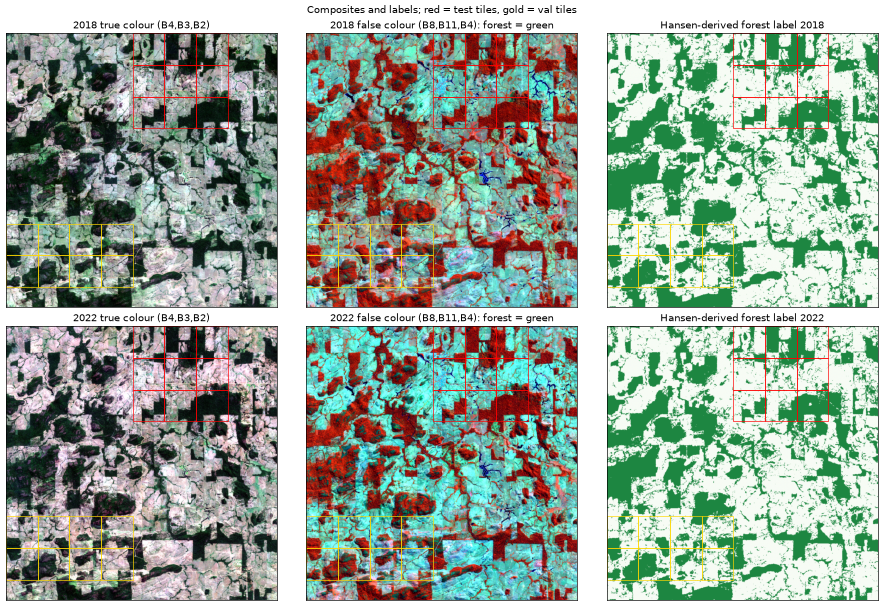

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10), layout="constrained")
for i, y in enumerate(YEARS):
    ax[i, 0].imshow(viz.rgb(img[y], ref=img[Y1])); ax[i, 0].set_title(f"{y} true colour (B4,B3,B2)")
    ax[i, 1].imshow(viz.rgb(img[y], bands=("B8", "B11", "B4"), ref=img[Y1])); ax[i, 1].set_title(f"{y} false colour (B8,B11,B4): forest = green")
    ax[i, 2].imshow(forest[y], cmap="Greens", vmin=0, vmax=1.3); ax[i, 2].set_title(f"Hansen-derived forest label {y}")
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
    for name, col in (("val", "gold"), ("test", "red")):
        for t in TILES[name]:
            a.add_patch(plt.Rectangle((t.col * SIZE, t.row * SIZE), SIZE, SIZE, fill=False, ec=col, lw=0.8))
fig.suptitle("Composites and labels; red = test tiles, gold = val tiles")
fig.savefig(FIGS / "data_overview.png", dpi=70)

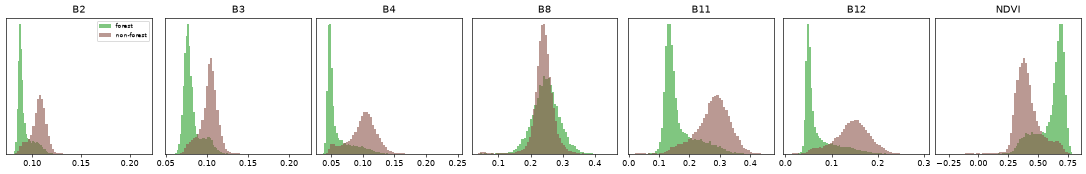

In [4]:
# Per-band reflectance for forest vs non-forest on train tiles: is the signal separable?
rng = np.random.default_rng(SEED)
Xs, ys = baselines.sample_pixels([img[Y1], img[Y2]], [forest[Y1], forest[Y2]], [t.window for t in TILES["train"]], 50000, SEED)
fig, ax = plt.subplots(1, 7, figsize=(18, 2.8), layout="constrained")
for i, b in enumerate(viz.BANDS):
    for cls, col in ((1, "tab:green"), (0, "tab:brown")):
        ax[i].hist(Xs[ys == cls, i] / 1e4, bins=60, alpha=0.6, color=col, density=True, label=["non-forest", "forest"][cls])
    ax[i].set_title(b); ax[i].set_yticks([])
nd = (Xs[:, 3] - Xs[:, 2]) / (Xs[:, 3] + Xs[:, 2])
for cls, col in ((1, "tab:green"), (0, "tab:brown")):
    ax[6].hist(nd[ys == cls], bins=60, alpha=0.6, color=col, density=True)
ax[6].set_title("NDVI"); ax[6].set_yticks([]); ax[0].legend(fontsize=7)
fig.savefig(FIGS / "band_histograms.png", dpi=70)

In [5]:
# PRODES (INPE) yearly deforestation polygons: independent of Hansen, used in sections 7 and 8.
prodes_path = Path(cfg.paths.raw) / "prodes_yearly_deforestation.geojson"
try:
    fc = json.loads(prodes_path.read_text()) if prodes_path.exists() else prodes.fetch(cfg.aoi.bbox, prodes_path)
    PRODES_YEARS = range(Y1 + 1, Y2 + 1)  # PRODES 2019..2022 = Aug 2018 .. Jul 2022
    prodes_loss = prodes.rasterize_years(fc, PRODES_YEARS, valid.shape, TRANSFORM, cfg.aoi.crs)
    prodes_before = prodes.rasterize_years(fc, range(1988, Y1 + 1), valid.shape, TRANSFORM, cfg.aoi.crs)
    print(len(fc["features"]), "PRODES polygons;", f"{PRODES_YEARS.start}-{PRODES_YEARS.stop - 1}:",
          round(metrics.area_ha(prodes_loss, TRANSFORM), 1), "ha in AOI")
except Exception as e:  # no fallback: section 8 states the limitation instead
    prodes_loss = None
    print("PRODES unavailable:", repr(e))

73 PRODES polygons; 2019-2022: 395.4 ha in AOI


## 2. Baselines

**NDVI threshold**: forest if NDVI ≥ t, with t chosen to maximise forest IoU on the **val** tiles (both years).
**Random forest**: per-pixel classifier on the 6 raw band values, trained on random pixels from the **train** tiles (both years).

NDVI threshold chosen on val: 0.52 (val IoU 0.5681)


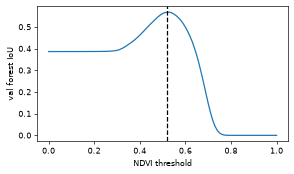

In [6]:
def stack(arrs, tiles):  # pixels of the given tiles, flattened
    return np.concatenate([a[t.window].ravel() for a in arrs for t in tiles])

nd = {y: baselines.ndvi(img[y]) for y in YEARS}
lo, hi, step = B["ndvi_grid"]
thr, table = baselines.best_ndvi_threshold(stack([nd[Y1], nd[Y2]], TILES["val"]),
                                           stack([forest[Y1], forest[Y2]], TILES["val"]),
                                           np.arange(lo, hi + 1e-9, step))
print(f"NDVI threshold chosen on val: {thr:.2f} (val IoU {max(r[1] for r in table):.4f})")
plt.figure(figsize=(5, 3)); plt.plot(*zip(*table)); plt.axvline(thr, ls="--", c="k")
plt.xlabel("NDVI threshold"); plt.ylabel("val forest IoU"); plt.tight_layout()

In [7]:
t0 = time.time()
Xtr, ytr = baselines.sample_pixels([img[Y1], img[Y2]], [forest[Y1], forest[Y2]],
                                   [t.window for t in TILES["train"]], B["rf_pixels"], SEED)
rf = baselines.fit_random_forest(Xtr, ytr, SEED, n_estimators=B["rf_trees"], max_depth=B["rf_max_depth"],
                                 n_jobs=B["rf_n_jobs"])
print(f"RF on {len(ytr):,} pixels, {B['rf_trees']} trees: {time.time() - t0:.0f}s; "
      f"feature importances {dict(zip(viz.BANDS, rf.feature_importances_.round(3)))}")

RF on 300,000 pixels, 200 trees: 9s; feature importances {'B2': np.float64(0.115), 'B3': np.float64(0.213), 'B4': np.float64(0.085), 'B8': np.float64(0.067), 'B11': np.float64(0.307), 'B12': np.float64(0.213)}


## 3. U-Net

`segmentation_models_pytorch` U-Net, ResNet-18 encoder, `in_channels=6`, trained on the train tiles of both years
(random flips/rotations), BCE + Dice loss, AdamW, cosine LR, model selection on **val** IoU.
Two runs with identical settings and seed: ImageNet-pretrained encoder vs random init.
Inputs are standardised with per-band mean/std from the train tiles only.

In [8]:
mean, std = data.band_stats([img[Y1], img[Y2]], TILES["train"])
norm = {y: data.normalize(img[y], mean, std) for y in YEARS}
np.savez(CKPT / "norm_stats.npz", mean=mean, std=std, bands=np.array(viz.BANDS))

def loaders():
    g = torch.Generator().manual_seed(SEED)
    tr = data.TileDataset(norm, forest, valid, TILES["train"], augment=True, repeats=U["repeats"])
    va = data.TileDataset(norm, forest, valid, TILES["val"])
    return (DataLoader(tr, batch_size=U["batch_size"], shuffle=True, generator=g, num_workers=U["num_workers"],
                       worker_init_fn=lambda w: np.random.seed(SEED + w), drop_last=True),
            DataLoader(va, batch_size=U["batch_size"], num_workers=U["num_workers"]))

histories, models = {}, {}
for name, weights in U["variants"].items():
    seed_everything(SEED)
    model = build_unet(U["encoder"], weights, U["in_channels"])
    opt = torch.optim.AdamW(model.parameters(), lr=U["lr"], weight_decay=U["weight_decay"])
    tr, va = loaders()
    trainer = Trainer(model, tr, va, opt, CKPT / f"unet_{name}", epochs=U["epochs"], patience=U["patience"],
                      use_amp=U["amp"], device=DEVICE, max_batches=ucfg.fast_dev_run.max_batches if FAST_DEV_RUN else None)
    t0 = time.time()
    histories[name] = trainer.fit()
    models[name] = trainer.load_best()
    save_json({"variant": name, "encoder_weights": weights, "best_epoch": trainer.best_epoch,
               "best_val_iou": trainer.best, "epochs_run": len(histories[name]),
               "train_time_s": round(time.time() - t0, 1), "config": U,
               "peak_gpu_mem_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE.type == "cuda" else None},
              f"train_unet_{name}.json")

epoch   1 loss 0.7471 val_iou 0.6788 (best 0.6788 @ 1) 16.7s


epoch   2 loss 0.5355 val_iou 0.6900 (best 0.6900 @ 2) 1.1s


epoch   3 loss 0.5092 val_iou 0.6835 (best 0.6900 @ 2) 1.1s


epoch   4 loss 0.5024 val_iou 0.6824 (best 0.6900 @ 2) 1.1s


epoch   5 loss 0.5112 val_iou 0.6905 (best 0.6905 @ 5) 1.1s


epoch   6 loss 0.4939 val_iou 0.6600 (best 0.6905 @ 5) 1.1s


... (55 outputs left out)

epoch  21 loss 0.4663 val_iou 0.6535 (best 0.6920 @ 3) 1.2s


epoch  22 loss 0.4667 val_iou 0.6471 (best 0.6920 @ 3) 1.2s


epoch  23 loss 0.4553 val_iou 0.6838 (best 0.6920 @ 3) 1.2s


early stop at epoch 23
wrote reports/metrics/train_unet_scratch.json


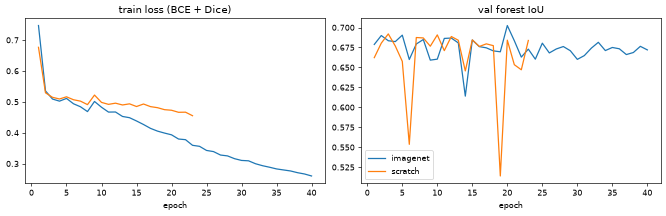

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for name, h in histories.items():
    e = [r["epoch"] for r in h]
    ax[0].plot(e, [r["train_loss"] for r in h], label=name)
    ax[1].plot(e, [r["val_iou"] for r in h], label=name)
ax[0].set_title("train loss (BCE + Dice)"); ax[1].set_title("val forest IoU"); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
fig.savefig(FIGS / "training_curves.png", dpi=80)

## 4. Test-tile metrics: forest mask

All four methods predict a forest mask for every val and test tile in both years. Scores pool the pixels of the 9 test tiles × 2 years.
The 95% CI resamples whole test tiles (tile-year pairs) with replacement, so it reflects how few independent test tiles there are.

In [10]:
def predict_method(method, year, tiles):
    out = {}
    if method.startswith("unet_"):
        x = torch.from_numpy(np.stack([norm[year][(slice(None),) + t.window] for t in tiles]))
        logits = predict_logits(models[method[5:]], x, DEVICE)
        for t, l in zip(tiles, logits):
            out[t.id] = l > 0
    for t in tiles:
        if method == "ndvi":
            out[t.id] = nd[year][t.window] >= thr
        elif method == "random_forest":
            out[t.id] = baselines.predict_random_forest(rf, img[year][(slice(None),) + t.window])
    return out

METHODS = ["ndvi", "random_forest"] + [f"unet_{n}" for n in U["variants"]]
PRED = {m: {s: {y: predict_method(m, y, TILES[s]) for y in YEARS} for s in ("val", "test")} for m in METHODS}

def tile_counts(pred_by_tile, truth, tiles):
    return [metrics.confusion(pred_by_tile[t.id], truth[t.window], valid[t.window]) for t in tiles]

forest_results, rows = {}, []
for m in METHODS:
    tc = [c for y in YEARS for c in tile_counts(PRED[m]["test"][y], forest[y], TILES["test"])]
    pooled = metrics.add(tc)
    res = {"pooled": {**metrics.scores(pooled), "counts": pooled},
           "ci95": metrics.bootstrap_ci(tc, n=C["bootstrap"], seed=SEED),
           "per_year": {y: metrics.scores(metrics.add(tile_counts(PRED[m]["test"][y], forest[y], TILES["test"]))) for y in YEARS}}
    forest_results[m] = res
    rows.append({"method": m, **{k: res["pooled"][k] for k in ("iou", "f1", "precision", "recall")},
                 "iou_ci95": "[{:.3f}, {:.3f}]".format(*res["ci95"]["iou"])})
save_json({"task": "forest mask", "split": "test", "n_tiles": len(TILES["test"]), "years": list(YEARS),
           "ndvi_threshold": thr, "results": forest_results}, "forest_mask_test.json")
forest_table = pd.DataFrame(rows).set_index("method")
forest_table.round(4)

wrote reports/metrics/forest_mask_test.json


,iou,f1,precision,recall,iou_ci95
method,,,,,
ndvi,0.7010,0.8242,0.8152,0.8334,"[0.607, 0.770]"
random_forest,0.7390,0.8499,0.8940,0.8100,"[0.649, 0.803]"
unet_imagenet,0.7561,0.8611,0.8825,0.8407,"[0.675, 0.815]"
unet_scratch,0.7462,0.8547,0.8695,0.8403,"[0.664, 0.806]"


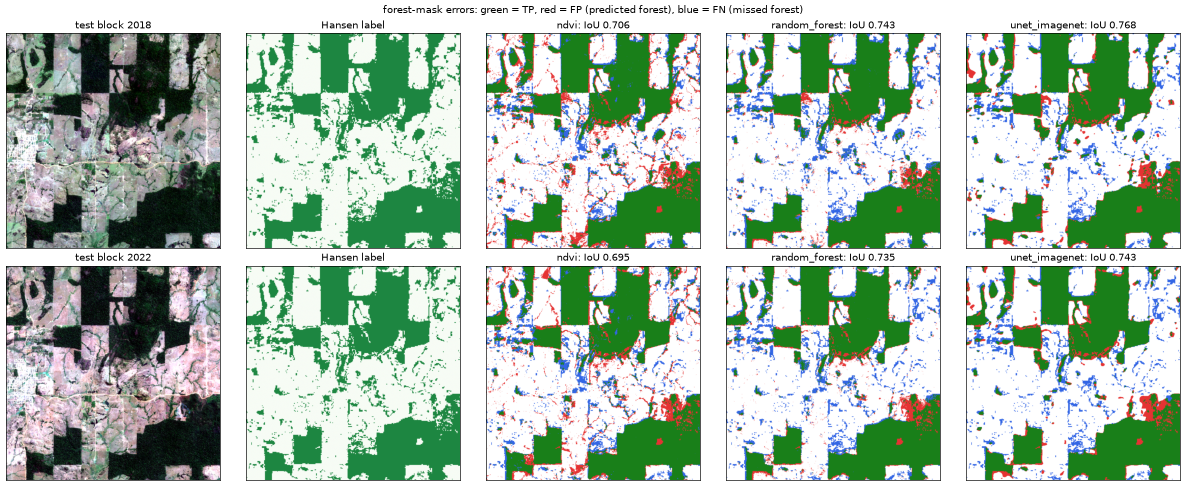

In [11]:
# Test block mosaic: label vs predictions, both years
cells = sorted((t.row, t.col) for t in TILES["test"])
r0, c0 = cells[0]; nr = cells[-1][0] - r0 + 1; nc = cells[-1][1] - c0 + 1
WIN = np.s_[r0 * SIZE:(r0 + nr) * SIZE, c0 * SIZE:(c0 + nc) * SIZE]

def mosaic(pred_by_tile):
    out = np.zeros((nr * SIZE, nc * SIZE), bool)
    for t in TILES["test"]:
        out[(t.row - r0) * SIZE:(t.row - r0 + 1) * SIZE, (t.col - c0) * SIZE:(t.col - c0 + 1) * SIZE] = pred_by_tile[t.id]
    return out

show = ["ndvi", "random_forest", "unet_imagenet"]
fig, ax = plt.subplots(2, 2 + len(show), figsize=(4 * (2 + len(show)), 8), layout="constrained")
for i, y in enumerate(YEARS):
    ax[i, 0].imshow(viz.rgb(img[y], ref=img[Y1])[WIN]); ax[i, 0].set_title(f"test block {y}")
    ax[i, 1].imshow(forest[y][WIN], cmap="Greens", vmin=0, vmax=1.3); ax[i, 1].set_title("Hansen label")
    for j, m in enumerate(show):
        em = change.error_map(mosaic(PRED[m]["test"][y]), forest[y][WIN])
        ax[i, 2 + j].imshow(np.array([[1, 1, 1], [0.1, 0.5, 0.1], [0.9, 0.2, 0.2], [0.2, 0.4, 0.9]])[em])
        ax[i, 2 + j].set_title(f"{m}: IoU {forest_results[m]['per_year'][y]['iou']:.3f}")
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
fig.suptitle("forest-mask errors: green = TP, red = FP (predicted forest), blue = FN (missed forest)")
fig.savefig(FIGS / "forest_mask_test.png", dpi=70)

## 5. Change detection 2018 → 2022

Predicted loss = predicted forest 2018 AND NOT predicted forest 2022, compared with Hansen loss.
**Hansen lossyear range: 2019–2022.** Composites span Jun–Sep of each year, and Hansen loss years are calendar years, so
2019–2022 is the closest match. It also equals forest(2018) AND NOT forest(2022) under the label rule. Caveats: loss in
Oct–Dec 2018 falls outside the window, and loss in Oct–Dec 2022 is counted although it happened after the 2022 composite.

Subtracting two independent masks produces speckle along forest edges, so a minimum mapping unit (drop loss blobs smaller
than *k* pixels) is chosen per method on the **val** tiles from `change.mmu_candidates_px` in `configs/unet.yaml`.

In [12]:
def loss_tiles(m, s, mmu):
    return {t.id: change.remove_small(change.loss_map(PRED[m][s][Y1][t.id], PRED[m][s][Y2][t.id]), mmu) for t in TILES[s]}

change_results, rows, MMU = {}, [], {}
for m in METHODS:
    val_iou = {k: metrics.scores(metrics.add(tile_counts(loss_tiles(m, "val", k), hloss, TILES["val"])))["iou"]
               for k in C["mmu_candidates_px"]}
    MMU[m] = max(val_iou, key=val_iou.get)
    raw_tc = tile_counts(loss_tiles(m, "test", 0), hloss, TILES["test"])
    tc = tile_counts(loss_tiles(m, "test", MMU[m]), hloss, TILES["test"])
    pooled = metrics.add(tc)
    change_results[m] = {"mmu_px": MMU[m], "val_iou_by_mmu": val_iou,
                         "pooled": {**metrics.scores(pooled), "counts": pooled},
                         "ci95": metrics.bootstrap_ci(tc, n=C["bootstrap"], seed=SEED),
                         "no_mmu": metrics.scores(metrics.add(raw_tc))}
    rows.append({"method": m, "mmu_px": MMU[m], **{k: change_results[m]["pooled"][k] for k in ("iou", "f1", "precision", "recall")},
                 "f1_ci95": "[{:.3f}, {:.3f}]".format(*change_results[m]["ci95"]["f1"]),
                 "f1_no_mmu": change_results[m]["no_mmu"]["f1"]})
save_json({"task": "forest loss", "reference": f"Hansen lossyear {Y1 + 1}-{Y2}", "split": "test",
           "results": change_results}, "change_test.json")
change_table = pd.DataFrame(rows).set_index("method")
change_table.round(4)

wrote reports/metrics/change_test.json


,mmu_px,iou,f1,precision,recall,f1_ci95,f1_no_mmu
method,,,,,,,
ndvi,100,0.2287,0.3722,0.3426,0.4074,"[0.132, 0.507]",0.2726
random_forest,50,0.3773,0.5478,0.5687,0.5284,"[0.327, 0.632]",0.4362
unet_imagenet,50,0.2801,0.4376,0.3434,0.6031,"[0.190, 0.564]",0.4139
unet_scratch,100,0.2201,0.3608,0.3200,0.4134,"[0.108, 0.491]",0.3381


best U-Net variant (by test forest IoU, used only for figures/area): unet_imagenet


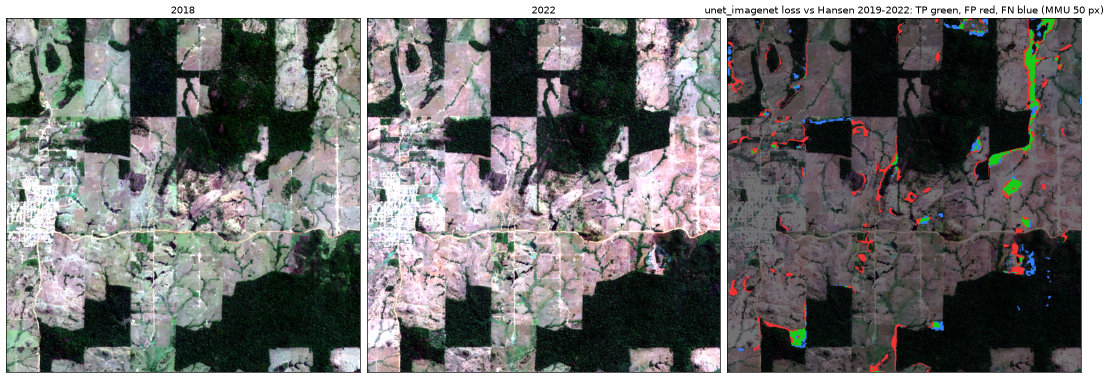

In [13]:
BEST = max((m for m in METHODS if m.startswith("unet_")), key=lambda m: forest_results[m]["pooled"]["iou"])
pred_loss = mosaic(loss_tiles(BEST, "test", MMU[BEST]))
true_loss = hloss[WIN]
em = change.error_map(pred_loss, true_loss)
pal = np.array([[0, 0, 0], [0.1, 0.8, 0.1], [0.95, 0.2, 0.2], [0.2, 0.5, 1.0]])
fig, ax = plt.subplots(1, 3, figsize=(18, 6.4), layout="constrained")
ax[0].imshow(viz.rgb(img[Y1], ref=img[Y1])[WIN]); ax[0].set_title(f"{Y1}")
ax[1].imshow(viz.rgb(img[Y2], ref=img[Y1])[WIN]); ax[1].set_title(f"{Y2}")
over = viz.rgb(img[Y2], ref=img[Y1])[WIN] * 0.45
over[em > 0] = pal[em[em > 0]]
ax[2].imshow(over)
ax[2].set_title(f"{BEST} loss vs Hansen {Y1 + 1}-{Y2}: TP green, FP red, FN blue (MMU {MMU[BEST]} px)")
for a in ax: a.set_xticks([]); a.set_yticks([])
fig.savefig(FIGS / "change_error_map.png", dpi=70)
print("best U-Net variant (by test forest IoU, used only for figures/area):", BEST)

## 6. Area lost (test tiles)

Each 10 m pixel is 0.01 ha (computed from the raster transform).

In [14]:
area = {"pixel_area_ha": metrics.pixel_area_ha(TRANSFORM), "hansen_ha": metrics.area_ha(true_loss, TRANSFORM)}
for m in METHODS:
    area[f"{m}_ha"] = metrics.area_ha(mosaic(loss_tiles(m, "test", MMU[m])), TRANSFORM)
if prodes_loss is not None:
    area["prodes_ha"] = metrics.area_ha(prodes_loss[WIN], TRANSFORM)
save_json({"split": "test", "years": f"{Y1 + 1}-{Y2}", "test_area_ha": metrics.area_ha(valid[WIN], TRANSFORM), **area}, "area_test.json")
pd.Series(area).round(2).to_frame("hectares (test tiles)")

wrote reports/metrics/area_test.json


,hectares (test tiles)
pixel_area_ha,0.01
hansen_ha,116.80
ndvi_ha,138.90
random_forest_ha,108.52
unet_imagenet_ha,205.14
unet_scratch_ha,150.91
prodes_ha,10.80


## 7. Error analysis

Each loss error pixel of the best U-Net on the test tiles gets one category, in priority order,
using only the Hansen layers (and PRODES when available):

* **FP** (model loss, no Hansen 2019–2022 loss): *PRODES 2019–22 deforestation* → *Hansen loss 2023+* (model sees a
  clearing Hansen dates later) → *Hansen loss ≤2018* → *canopy < threshold in 2000* (outside the label definition,
  e.g. secondary vegetation) → *forest edge* (≤2 px from the Hansen 2018 forest boundary) → *stable forest interior*.
* **FN** (Hansen loss the model missed): *model: non-forest already in 2018* or *model: still forest in 2022*,
  split into *edge* (≤2 px from the Hansen loss patch boundary) vs *interior*.

Then the 10 largest FP and FN blobs are shown.

In [15]:
LY_T = lossyear[WIN].astype(int); TC_T = treecover[WIN]
f18_hansen = forest[Y1][WIN]
near_forest_edge = ndimage.binary_dilation(viz.edges(f18_hansen) | viz.edges(~f18_hansen), iterations=2)
near_loss_edge = ndimage.binary_dilation(viz.edges(true_loss) | viz.edges(~true_loss), iterations=2)
pf18, pf22 = mosaic(PRED[BEST]["test"][Y1]), mosaic(PRED[BEST]["test"][Y2])
fp, fn = em == change.FP, em == change.FN

fp_cat = np.full(fp.shape, "", object)
rules = []
if prodes_loss is not None:
    rules.append(("PRODES 2019-22 deforestation", prodes_loss[WIN]))
rules += [("Hansen loss 2023+", LY_T >= Y2 - 2000 + 1), ("Hansen loss <=2018", (LY_T >= 1) & (LY_T <= Y1 - 2000)),
          ("canopy2000 < threshold", TC_T < cfg.labels.treecover_threshold), ("forest edge (<=2 px)", near_forest_edge),
          ("stable forest interior", np.ones_like(fp))]
for name, cond in rules:
    sel = fp & (fp_cat == "") & cond
    fp_cat[sel] = name
fn_cat = np.full(fn.shape, "", object)
fn_cat[fn & ~pf18] = "model: non-forest in 2018"
fn_cat[fn & pf18 & pf22] = "model: still forest in 2022"
fn_cat[fn & pf18 & ~pf22] = "removed by MMU"
fn_cat[fn] = fn_cat[fn] + np.where(near_loss_edge[fn], ", edge", ", interior")

def summarise(cat, mask):
    names, counts = np.unique(cat[mask], return_counts=True)
    return {str(n): {"pixels": int(c), "share": round(float(c / mask.sum()), 4)} for n, c in sorted(zip(names, counts), key=lambda x: -x[1])}

err = {"method": BEST, "fp_pixels": int(fp.sum()), "fn_pixels": int(fn.sum()),
       "fp_categories": summarise(fp_cat, fp), "fn_categories": summarise(fn_cat, fn)}
save_json(err, "error_analysis.json")
pd.concat({"FP": pd.DataFrame(err["fp_categories"]).T, "FN": pd.DataFrame(err["fn_categories"]).T})

wrote reports/metrics/error_analysis.json


pixels   share
FP canopy2000 < threshold                 4020.0  0.2984
   forest edge (<=2 px)                   3834.0  0.2846
   Hansen loss <=2018                     3075.0  0.2283
   stable forest interior                 1857.0  0.1379
   Hansen loss 2023+                       502.0  0.0373
   PRODES 2019-22 deforestation            182.0  0.0135
FN model: still forest in 2022, edge      3302.0  0.7123
   model: non-forest in 2018, edge         672.0  0.1450
   model: still forest in 2022, interior   550.0  0.1186
   removed by MMU, edge                     82.0  0.0177
   model: non-forest in 2018, interior      30.0  0.0065

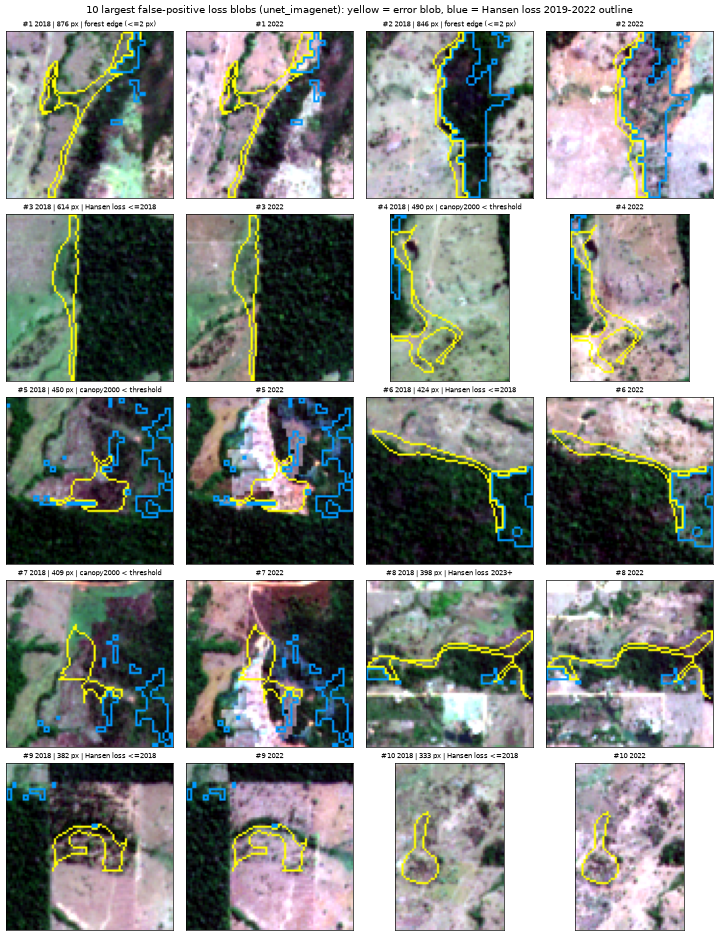

In [16]:
def gallery(mask, cat, title, fname, n=10, half=40):
    blobs = change.components(mask)[:n]
    fig, ax = plt.subplots(n // 2, 4, figsize=(12, 3.1 * (n // 2)), layout="constrained")
    rgb1, rgb2 = viz.rgb(img[Y1], ref=img[Y1])[WIN], viz.rgb(img[Y2], ref=img[Y1])[WIN]
    info = []
    for k, (size, sl, blob) in enumerate(blobs):
        cy, cx = (sl[0].start + sl[0].stop) // 2, (sl[1].start + sl[1].stop) // 2
        ys = slice(max(cy - half, 0), cy + half); xs = slice(max(cx - half, 0), cx + half)
        full = np.zeros(mask.shape, bool); full[sl] = blob
        e = viz.edges(full[ys, xs]) | viz.edges(true_loss[ys, xs])
        main = pd.Series(cat[sl][blob]).value_counts().index[0]
        for j, (r, yr) in enumerate(((rgb1, Y1), (rgb2, Y2))):
            a = ax[k // 2, 2 * (k % 2) + j]
            o = viz.overlay(r[ys, xs], viz.edges(full[ys, xs]), (1, 1, 0))
            o = viz.overlay(o, viz.edges(true_loss[ys, xs]) & ~viz.edges(full[ys, xs]), (0, 0.6, 1))
            a.imshow(o); a.set_xticks([]); a.set_yticks([])
            a.set_title(f"#{k + 1} {yr}" + (f" | {size} px | {main}" if j == 0 else ""), fontsize=8)
        info.append({"rank": k + 1, "pixels": size, "row": int(r0 * SIZE + cy), "col": int(c0 * SIZE + cx), "main_category": main})
    fig.suptitle(f"{title}: yellow = error blob, blue = Hansen loss {Y1 + 1}-{Y2} outline")
    fig.savefig(FIGS / fname, dpi=70)
    return info

fp_info = gallery(fp, fp_cat, f"10 largest false-positive loss blobs ({BEST})", "errors_fp.png")

wrote reports/metrics/error_analysis.json


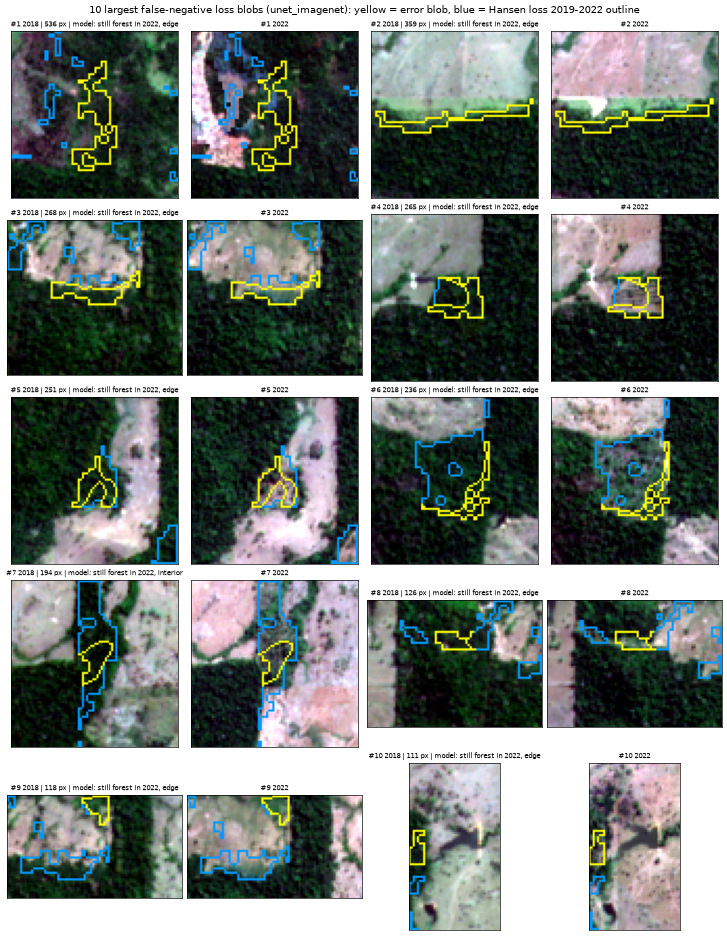

In [17]:
fn_info = gallery(fn, fn_cat, f"10 largest false-negative loss blobs ({BEST})", "errors_fn.png")
err["fp_gallery"], err["fn_gallery"] = fp_info, fn_info
save_json(err, "error_analysis.json")

**Visual reading of the galleries** (my interpretation of the 20 thumbnails above; the pixel shares in the table are computed, these notes are not):

*False positives*, where the model says loss and Hansen says no loss 2019–2022:
- **Thin slivers along forest edges and tree lines** (#1, #3, #6, #8). The image shows little or no change. The 2018 and 2022 masks disagree by 1–3 pixels at the edge, and differencing turns that into "loss". This is the main weakness of change detection by subtracting two masks.
- **Clearing of secondary vegetation or regrowth** (#4, #5, #7, #9). The 2022 image shows a real new clearing, but the area had < 30% canopy in 2000 or was already lost before 2019. The label definition (canopy in 2000, no regrowth) excludes it, so the model is "wrong" only against the label.
- **Thinning or degradation** of a forest strip (#2), and sparse trees in pasture (#10). Both are ambiguous.

*False negatives*, where Hansen says loss and the model misses it:
- **Edge expansion of existing clearings** by 1–3 Hansen (30 m) pixels (#2, #3, #8, #9). Hansen's 30 m edges don't match 10 m Sentinel-2 edges, and the model keeps the edge as forest in 2022.
- **Degraded but not cleared forest** (#1, #4, #6). The 2022 canopy looks darker or thinned (fire or selective logging), not bare. Hansen counts this as loss; the model still sees forest.
- **Narrow riparian corridors** (#7, #10) that partly remain in 2022.

## 8. Independent check (PRODES) and limitations

Labels come from Hansen, so agreement with Hansen is partly circular: a model that copies Hansen well scores well even where
Hansen is wrong. [PRODES](https://terrabrasilis.dpi.inpe.br/) (INPE) is an independent, visually interpreted Landsat
product. It maps **clear-cut of primary forest only**, with a minimum polygon of 6.25 ha (1 ha in recent years), and masks
anything deforested earlier. So PRODES is a stricter definition of loss than Hansen: expect high recall against PRODES and
lower precision. PRODES years 2019–2022 cover about Aug 2018 – Jul 2022, which matches the composite dates well.

In [18]:
if prodes_loss is None:
    print("PRODES not available in this run; the comparison is skipped and stated as a limitation.")
    prodes_results = None
else:
    pl = prodes_loss[WIN]
    prodes_results = {"reference": "PRODES yearly_deforestation 2019-2022 (TerraBrasilis WFS)",
                      "hansen_vs_prodes": metrics.scores(metrics.confusion(true_loss, pl, valid[WIN])),
                      "hansen_vs_prodes_whole_aoi": metrics.scores(metrics.confusion(hloss, prodes_loss, valid))}
    for m in METHODS:
        prodes_results[f"{m}_vs_prodes"] = metrics.scores(metrics.confusion(mosaic(loss_tiles(m, "test", MMU[m])), pl, valid[WIN]))
    prodes_results["prodes_test_ha"] = metrics.area_ha(pl, TRANSFORM)
    save_json(prodes_results, "prodes_test.json")
    display(pd.DataFrame({k: v for k, v in prodes_results.items() if isinstance(v, dict)}).T[["iou", "f1", "precision", "recall"]].round(4))

wrote reports/metrics/prodes_test.json


,iou,f1,precision,recall
hansen_vs_prodes,0.0109,0.0215,0.0117,0.1269
hansen_vs_prodes_whole_aoi,0.1612,0.2777,0.1844,0.5615
ndvi_vs_prodes,0.0366,0.0707,0.0381,0.4898
random_forest_vs_prodes,0.0474,0.0905,0.0498,0.5000
unet_imagenet_vs_prodes,0.0133,0.0262,0.0138,0.2620
unet_scratch_vs_prodes,0.0387,0.0746,0.0400,0.5583


**Limitations**

* Labels are Hansen-derived: test scores measure agreement with Hansen, which has its own errors (see section 7).
* 9 test tiles from one 22 km × 22 km area: the CIs are wide and the numbers say nothing about other regions.
* L1C top-of-atmosphere reflectance (no atmospheric correction); both years are processed identically.
* Hansen loss years are calendar years while composites are Jun–Sep, so loss timing at the window edges is ambiguous.
* The forest definition (≥30% canopy in 2000, no later loss) ignores regrowth after 2000.
* Change is detected by differencing two independent masks, so errors in either year become loss errors.